In [ ]:

import pandas as pd

# Load cleaned dataset
df = pd.read_csv("cleaned_sales_dataset.csv")

# Convert order date
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# Reference date: one day after the latest transaction
reference_date = df["Order_Date"].max() + pd.Timedelta(days=1)

# Customer-level aggregation
customer_data = df.groupby("Customer_ID").agg(
    Frequency=("Order_ID", "size"),
    Monetary=("Total_Sales", "sum"),
    Last_Purchase=("Order_Date", "max")
).reset_index()

# Calculate Recency
customer_data["Recency"] = (
    reference_date - customer_data["Last_Purchase"]
).dt.days

# Calculate KPIs
total_customers = customer_data["Customer_ID"].nunique()

repeat_customers = (
    customer_data["Frequency"] > 1
).sum()

repeat_rate = (
    repeat_customers / total_customers
) * 100

avg_frequency = customer_data["Frequency"].mean()

avg_customer_spend = customer_data["Monetary"].mean()

avg_recency = customer_data["Recency"].mean()

# Display KPI results
print("CUSTOMER KPI REPORT")
print("-------------------------")
print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("Repeat Customer Rate:", round(repeat_rate, 2), "%")
print("Average Purchase Frequency:", round(avg_frequency, 2))
print("Average Customer Spend:", round(avg_customer_spend, 2))
print("Average Recency:", round(avg_recency, 2), "days")

# Save customer-level data
customer_data.to_csv(
    "customer_rfm_base.csv",
    index=False
)


CUSTOMER KPI REPORT
-------------------------
Total Customers: 947
Repeat Customers: 52
Repeat Customer Rate: 5.49 %
Average Purchase Frequency: 1.06
Average Customer Spend: 147201.1
Average Recency: 178.78 days


In [ ]:

# RFM Scoring

# Recency: lower days = better score
customer_data["R_Score"] = pd.qcut(
    customer_data["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: custom scoring for this dataset
customer_data["F_Score"] = customer_data["Frequency"].apply(
    lambda x: 1 if x == 1 else (3 if x == 2 else 5)
)

# Monetary: higher spending = better score
customer_data["M_Score"] = pd.qcut(
    customer_data["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
customer_data["RFM_Score"] = (
    customer_data["R_Score"]
    + customer_data["F_Score"]
    + customer_data["M_Score"]
)

# Customer segmentation
customer_data["Segment"] = "Needs Attention"

customer_data.loc[
    customer_data["R_Score"] <= 2,
    "Segment"
] = "At Risk / Inactive"

customer_data.loc[
    (customer_data["R_Score"] >= 4) &
    (customer_data["F_Score"] == 1),
    "Segment"
] = "Recent One-time Customers"

customer_data.loc[
    (customer_data["R_Score"] >= 3) &
    (customer_data["F_Score"] >= 3),
    "Segment"
] = "Loyal Customers"

customer_data.loc[
    (customer_data["R_Score"] >= 4) &
    (customer_data["F_Score"] >= 3) &
    (customer_data["M_Score"] >= 4),
    "Segment"
] = "Champions"

# Display results
print(customer_data.head(10))

# Save results
customer_data.to_csv("customer_rfm_segments.csv", index=False)


  Customer_ID  Frequency   Monetary Last_Purchase  Recency  R_Score  F_Score  \
0    CUST1004          1    8321.54    2025-02-24      312        1        1   
1    CUST1017          1  264230.68    2025-04-16      261        2        1   
2    CUST1026          1  164965.29    2025-09-29       95        4        1   
3    CUST1032          1  146990.90    2025-04-28      249        2        1   
4    CUST1038          1   37068.40    2025-05-06      241        2        1   
5    CUST1049          1   16714.64    2025-03-09      299        1        1   
6    CUST1088          1  203819.75    2025-08-27      128        4        1   
7    CUST1090          1    5263.79    2025-12-31        2        5        1   
8    CUST1094          1  211945.90    2025-06-20      196        3        1   
9    CUST1104          1   90746.36    2025-04-02      275        2        1   

   M_Score  RFM_Score                    Segment  
0        1          3         At Risk / Inactive  
1        5       

In [ ]:
segment_summary = customer_data.groupby("Segment").agg(
    Customer_Count=("Customer_ID", "count"),
    Total_Revenue=("Monetary", "sum"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean")
).reset_index()

segment_summary["Revenue_Percentage"] = (
    segment_summary["Total_Revenue"] /
    customer_data["Monetary"].sum()
) * 100

print(segment_summary)

                     Segment  Customer_Count  Total_Revenue  Avg_Recency  \
0         At Risk / Inactive             379    53238182.48   289.546174   
1                  Champions              30    10087602.81    57.300000   
2            Loyal Customers              16     3497586.46   131.062500   
3            Needs Attention             181    25106970.09   179.585635   
4  Recent One-time Customers             341    47469097.81    68.167155   

   Avg_Frequency  Revenue_Percentage  
0       1.015831           38.191102  
1       2.033333            7.236473  
2       2.000000            2.509039  
3       1.000000           18.010811  
4       1.000000           34.052574  


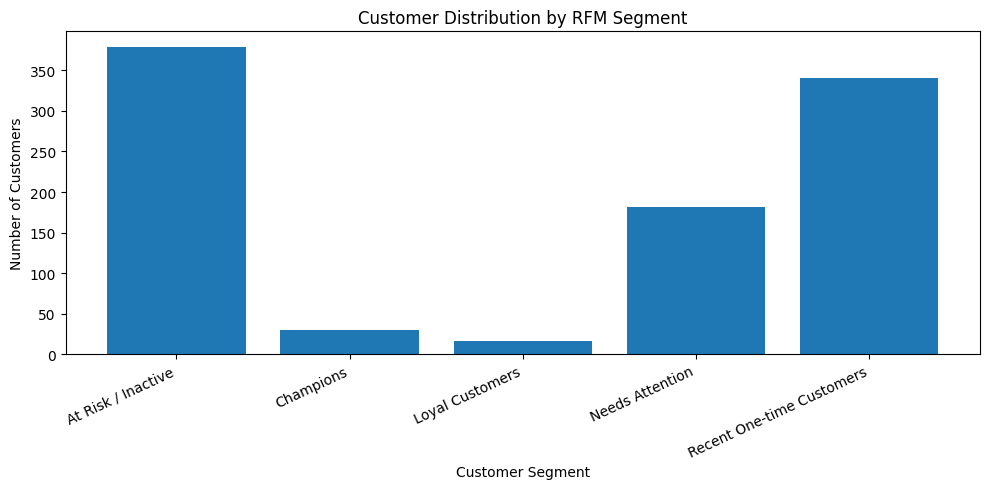

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Customer_Count"]
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
for _, row in segment_summary.iterrows():
    print(
        f"{row['Segment']}: "
        f"₹{row['Total_Revenue']:,.2f} "
        f"({row['Revenue_Percentage']:.2f}%)"
    )

At Risk / Inactive: ₹53,238,182.48 (38.19%)
Champions: ₹10,087,602.81 (7.24%)
Loyal Customers: ₹3,497,586.46 (2.51%)
Needs Attention: ₹25,106,970.09 (18.01%)
Recent One-time Customers: ₹47,469,097.81 (34.05%)


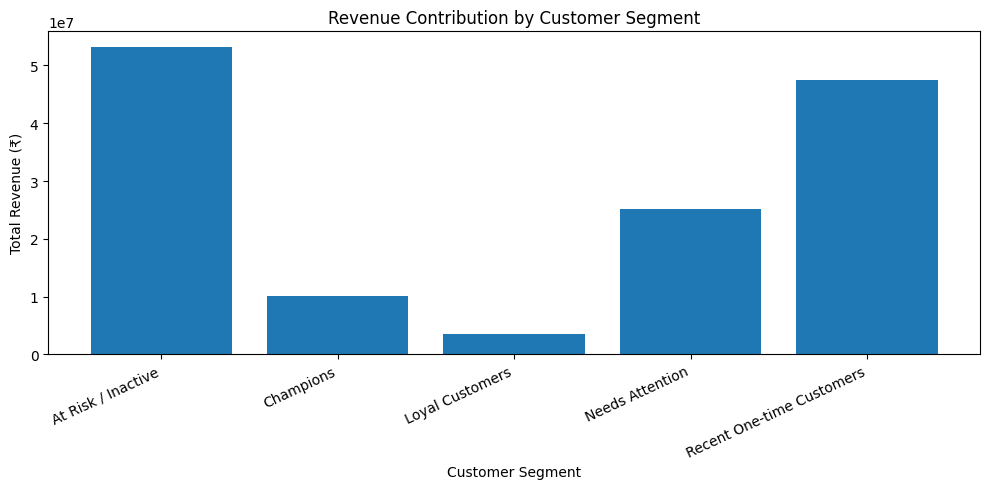

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Total_Revenue"]
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
# Select the columns required for the dashboard
final_rfm = customer_data[
    [
        "Customer_ID",
        "Frequency",
        "Monetary",
        "Last_Purchase",
        "Recency",
        "R_Score",
        "F_Score",
        "M_Score",
        "RFM_Score",
        "Segment"
    ]
]

# Export the final dataset
final_rfm.to_csv("customer_rfm_segments.csv", index=False)

print("Final RFM dataset created successfully!")
print("Shape:", final_rfm.shape)
print(final_rfm.head())

Final RFM dataset created successfully!
Shape: (947, 10)
  Customer_ID  Frequency   Monetary Last_Purchase  Recency  R_Score  F_Score  \
0    CUST1004          1    8321.54    2025-02-24      312        1        1   
1    CUST1017          1  264230.68    2025-04-16      261        2        1   
2    CUST1026          1  164965.29    2025-09-29       95        4        1   
3    CUST1032          1  146990.90    2025-04-28      249        2        1   
4    CUST1038          1   37068.40    2025-05-06      241        2        1   

   M_Score  RFM_Score                    Segment  
0        1          3         At Risk / Inactive  
1        5          8         At Risk / Inactive  
2        4          9  Recent One-time Customers  
3        4          7         At Risk / Inactive  
4        1          4         At Risk / Inactive  
